# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** Michelle Marcelina
- **Email:** amnez.co@gmail.com
- **ID Dicoding:**

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Pada musim apa rata-rata jumlah penyewaan sepeda harian paling tinggi selama periode 2011–2012?

- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda oleh pengguna kasual dan pengguna terdaftar antara kondisi cuaca cerah dan buruk selama periode 2011–2012, serta kelompok pengguna mana yang mengalami penurunan persentase paling besar?

- **Pertanyaan 3:** Pada jam berapa rata-rata jumlah penyewaan sepeda paling tinggi dan paling rendah, serta pada jam berapa jumlah penyewaan mengalami perubahan paling besar selama periode 2011–2012?


## Import Semua Packages/Library yang Digunakan

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Data Wrangling

### Gathering Data

#### Load df ...

In [75]:
# Membaca dataset
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 baris pertama dari masing-masing dataset
print("Dataset Harian:")
display(day_df.head())

print("Dataset Per Jam:")
display(hour_df.head())


print("Ukuran day_df:", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)


Dataset Harian:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Dataset Per Jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Ukuran day_df: (731, 16)
Ukuran hour_df: (17379, 17)


### Assessing Data

#### Identifying ... problem

In [87]:
# Memeriksa struktur dataset
day_df.info()
hour_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

In [88]:
# Memeriksa tipe data
print("Tipe data dteday pada dataset day:", day_df["dteday"].dtype)
print("Tipe data dteday pada dataset hour:", hour_df["dteday"].dtype)

# Memeriksa nilai
print("Contoh nilai kolom dteday pada dataset day:")
print(day_df["dteday"].head())

print("\nContoh nilai kolom dteday pada dataset per hour:")
print(hour_df["dteday"].head())


Tipe data dteday pada dataset day: object
Tipe data dteday pada dataset hour: object
Contoh nilai kolom dteday pada dataset day:
0    2011-01-01
1    2011-01-02
2    2011-01-03
3    2011-01-04
4    2011-01-05
Name: dteday, dtype: object

Contoh nilai kolom dteday pada dataset per hour:
0    2011-01-01
1    2011-01-01
2    2011-01-01
3    2011-01-01
4    2011-01-01
Name: dteday, dtype: object


In [89]:
# Memeriksa duplicate data
print("Jumlah duplikat pada dataset day:", day_df.duplicated().sum())
print("Jumlah duplikat pada dataset hour:", hour_df.duplicated().sum())


Jumlah duplikat pada dataset day: 0
Jumlah duplikat pada dataset hour: 0


In [90]:
# Memeriksa missing values
print("Missing values day:")
print(day_df.isnull().sum())

print("\nMissing values hour:")
print(hour_df.isnull().sum())


Missing values day:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing values hour:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [91]:
# Memeriksa nilai negatif

#day
print("Nilai negatif pada dataset day:")
print((day_df[["casual", "registered", "cnt"]] < 0).sum())

#hour
print("\nNilai negatif pada dataset hour:")
print((hour_df[["casual", "registered", "cnt"]] < 0).sum())


Nilai negatif pada dataset day:
casual        0
registered    0
cnt           0
dtype: int64

Nilai negatif pada dataset hour:
casual        0
registered    0
cnt           0
dtype: int64


In [92]:
# Memeriksa konsistensi jumlah penyewaan

#day
print(
    "Ketidaksesuaian pada dataset day:",
    (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum()
)

#hour
print(
    "Ketidaksesuaian pada dataset hour:",
    (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum()
)

Ketidaksesuaian pada dataset day: 0
Ketidaksesuaian pada dataset hour: 0


In [93]:
#Memeriksa nilai unik pada kolom kategorikal

categorical_columns = [
    "season", "yr", "mnth", "holiday",
    "weekday", "workingday", "weathersit"
]

print("Nilai unik pada dataset day:")
for col in categorical_columns:
    print(f"{col}: {sorted(day_df[col].unique())}")

print("\nNilai unik pada dataset hour:")
for col in categorical_columns:
    print(f"{col}: {sorted(hour_df[col].unique())}")

Nilai unik pada dataset day:
season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr: [np.int64(0), np.int64(1)]
mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday: [np.int64(0), np.int64(1)]
weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday: [np.int64(0), np.int64(1)]
weathersit: [np.int64(1), np.int64(2), np.int64(3)]

Nilai unik pada dataset hour:
season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr: [np.int64(0), np.int64(1)]
mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday: [np.int64(0), np.int64(1)]
weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday: [np.int64(0), np.int64(1)]
weathersit: [np.int6

**Steps to Take:**

- Mengubah tipe data kolom dteday pada dataset day_df dan hour_df dari object menjadi datetime agar sesuai dengan fungsi kolom tanggal.
- Memastikan kembali tipe data dan kondisi dataset setelah proses pembersihan dilakukan.
- Memeriksa nilai negatif pada kolom `casual`, `registered`, dan `cnt`. Tidak ditemukan nilai negatif pada kedua dataset.
- Mempertahankan data yang sudah memenuhi kriteria pemeriksaan, karena tidak ditemukan data duplikat, missing values, nilai negatif pada jumlah penyewaan, maupun ketidaksesuaian antara casual, registered, dan cnt.
- Melanjutkan ke tahap analisis data setelah proses pembersihan selesai.



**Insight:**
- Dataset `day` memiliki 731 baris, sedangkan dataset `hour` memiliki 17.379 baris.
- Tidak ditemukan data duplikat dan missing values pada kedua dataset juga nilai negatif pada jumlah penyewaan.
- Jumlah `casual` dan `registered` sesuai dengan nilai `cnt` pada kedua dataset.
- Kolom `dteday` masih bertipe `object` sehingga perlu diubah menjadi `datetime`.

### Cleaning Data

#### Fixing ... problem

In [99]:
# Mengubah tipe data dteday menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Memeriksa hasil cleaning
print("Tipe data dteday pada day_df:", day_df["dteday"].dtype)
print("Tipe data dteday pada hour_df:", hour_df["dteday"].dtype)

print("\nMissing values pada dteday day_df:", day_df["dteday"].isnull().sum())
print("Missing values pada dteday hour_df:", hour_df["dteday"].isnull().sum())

Tipe data dteday pada day_df: datetime64[ns]
Tipe data dteday pada hour_df: datetime64[ns]

Missing values pada dteday day_df: 0
Missing values pada dteday hour_df: 0


**Insight:**
- Tipe data kolom `dteday` pada dataset `day_df` dan `hour_df` sudah berhasil diubah menjadi `datetime`dan tidak ditemukan missing values pada kolom `dteday` setelah proses perubahan tipe data sehingga data tsb dapat digunakan untuk analisis berdasarkan waktu.

## Exploratory Data Analysis (EDA)

### Explore ...

In [28]:
# Menghitung rata-rata penyewaan sepeda berdasarkan musim
season_rentals = day_df.groupby("season")["cnt"].mean().reset_index()

# Mengurutkan berdasarkan rata-rata penyewaan tertinggi
season_rentals = season_rentals.sort_values(
    by="cnt", ascending=False
)

display(season_rentals)


,season,cnt
2,3,5644.303191
1,2,4992.331522
3,4,4728.162921
0,1,2604.132597


In [109]:
# Menghitung rata-rata penyewaan saat cuaca cerah
cerah = day_df[day_df["weathersit"] == 1][
    ["casual", "registered"]
].mean()

# Menghitung rata-rata penyewaan saat cuaca buruk
cuaca_buruk = day_df[day_df["weathersit"].isin([3, 4])][
    ["casual", "registered"]
].mean()

# Membandingkan rata-rata penyewaan
weather_comparison = pd.DataFrame({
    "Cerah": cerah,
    "Cuaca Buruk": cuaca_buruk
})

display(weather_comparison)

# Menghitung persentase penurunan
penurunan = (
    (cerah - cuaca_buruk) / cerah
) * 100

print("\nPersentase penurunan penyewaan:")
print(f"Pengguna kasual: {penurunan['casual']:.2f}%")
print(f"Pengguna terdaftar: {penurunan['registered']:.2f}%")



,Cerah,Cuaca Buruk
casual,964.030238,185.476190
registered,3912.755940,1617.809524



Persentase penurunan penyewaan:
Pengguna kasual: 80.76%
Pengguna terdaftar: 58.65%


In [115]:
# Menghitung rata-rata penyewaan sepeda berdasarkan jam
hourly_rentals = hour_df.groupby("hr")["cnt"].mean().reset_index()

# Menampilkan hasil rata-rata penyewaan setiap jam
display(hourly_rentals)



# Mencari jam dengan rata-rata penyewaan tertinggi dan terendah
jam_tertinggi = hourly_rentals.loc[hourly_rentals["cnt"].idxmax()]
jam_terendah = hourly_rentals.loc[hourly_rentals["cnt"].idxmin()]

print("Rata-rata penyewaan tertinggi:")
print(f"Jam {int(jam_tertinggi['hr'])}:00 = {jam_tertinggi['cnt']:.2f} penyewaan")

print("\nRata-rata penyewaan terendah:")
print(f"Jam {int(jam_terendah['hr'])}:00 = {jam_terendah['cnt']:.2f} penyewaan")

# Menghitung perubahan rata-rata antara jam yang berurutan
hourly_rentals["perubahan"] = hourly_rentals["cnt"].diff()
hourly_rentals["perubahan_absolut"] = hourly_rentals["perubahan"].abs()

# Mencari perubahan terbesar
perubahan_terbesar = hourly_rentals.loc[
    hourly_rentals["perubahan_absolut"].idxmax()
]

jam_sebelumnya = int(perubahan_terbesar["hr"]) - 1
jam_sekarang = int(perubahan_terbesar["hr"])

print("\nPerubahan rata-rata terbesar:")
print(
    f"Dari jam {jam_sebelumnya:02d}:00 ke jam {jam_sekarang:02d}:00, "
    f"perubahan sebesar {perubahan_terbesar['perubahan']:.2f} penyewaan"
)

,hr,cnt
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


Rata-rata penyewaan tertinggi:
Jam 17:00 = 461.45 penyewaan

Rata-rata penyewaan terendah:
Jam 4:00 = 6.35 penyewaan

Perubahan rata-rata terbesar:
Dari jam 16:00 ke jam 17:00, perubahan sebesar 149.47 penyewaan


**Insight:**

Pada penyewaan sepeda berdasarkan musim,
- Rata-rata penyewaan sepeda paling tinggi terjadi pada musim *Fall*, yaitu sekitar 5.644 sepeda per hari. Sebaliknya, musim *Spring* memiliki rata-rata penyewaan paling rendah, yaitu sekitar 2.604 sepeda per hari. Hal ini menunjukkan bahwa musim *Fall* menjadi musim dengan jumlah penyewaan sepeda harian tertinggi selama periode 2011–2012.

Pada penyewaan sepeda berdasarkan cuaca,
- cuaca cerah, rata-rata penyewaan oleh pengguna kasual mencapai 964,03, sedangkan pengguna terdaftar mencapai 3.912,76.
- cuaca buruk, jumlah tersebut turun menjadi 185,48 untuk pengguna kasual dan 1.617,81 untuk pengguna terdaftar.

hasil persentase penurunannya, pengguna kasual mengalami penurunan sebesar 80,76%, sedangkan pengguna terdaftar sebesar 58,65%. Artinya, penyewaan oleh pengguna kasual mengalami penurunan yang lebih besar saat cuaca buruk dibandingkan pengguna terdaftar.

Pada penyewaan sepeda berdasarkan jam
- Penyewaan sepeda paling ramai terjadi pada pukul 17.00, dengan rata-rata 461,45 penyewaan.
- Pukul 04.00 menjadi waktu dengan rata-rata penyewaan paling rendah, yaitu 6,35 penyewaan.
- Kenaikan rata-rata paling besar terjadi dari pukul 16.00 ke 17.00, yaitu sebanyak 149,47 penyewaan. Ini menunjukkan bahwa penyewaan sepeda meningkat menjelang sore dan mencapai rata-rata tertinggi pada pukul 17.00.

## Visualization & Explanatory Analysis

### Pertanyaan 1:Pada musim apa rata-rata jumlah penyewaan sepeda harian paling tinggi selama periode 2011–2012?



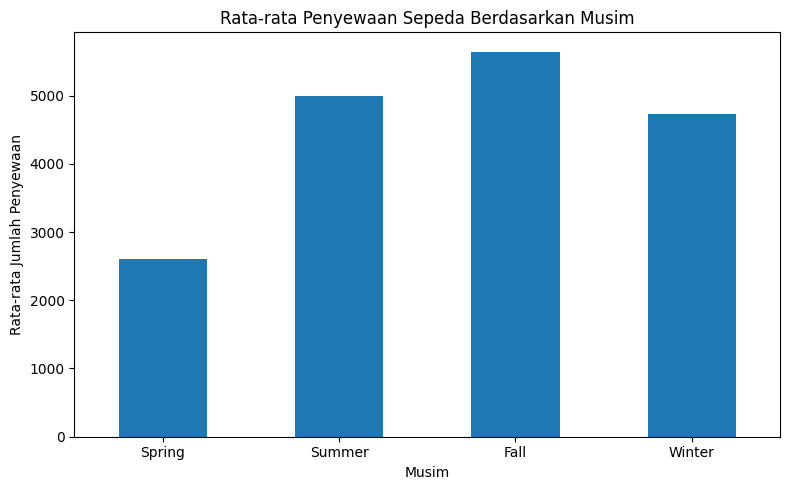

In [29]:
# Mengurutkan musim sesuai kode agar grafik mudah dibaca
season_plot = day_df.groupby("season")["cnt"].mean()

season_names = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

season_plot.index = season_plot.index.map(season_names)

# Membuat bar chart
plt.figure(figsize=(8, 5))
season_plot.plot(kind="bar")

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda oleh pengguna kasual dan pengguna terdaftar antara kondisi cuaca cerah dan buruk selama periode 2011–2012, serta kelompok pengguna mana yang mengalami penurunan persentase paling besar?



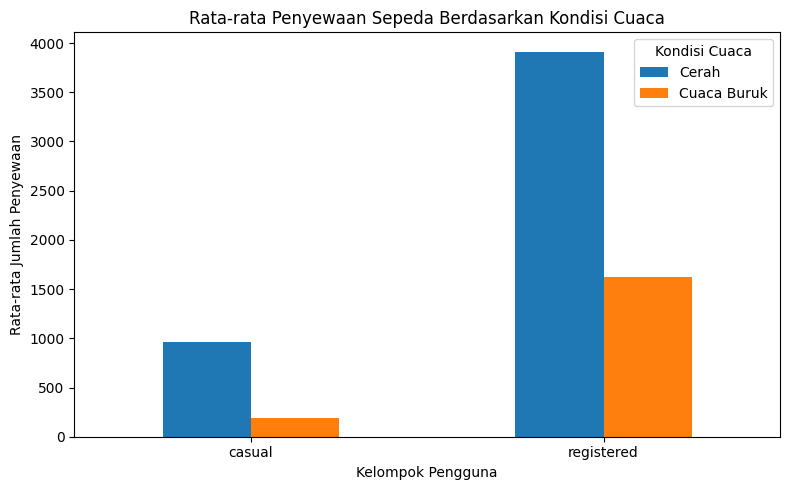

In [110]:
# Membuat grafik perbandingan rata-rata penyewaan
weather_comparison.plot(kind="bar", figsize=(8, 5))

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
plt.xlabel("Kelompok Pengguna")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(rotation=0)
plt.legend(title="Kondisi Cuaca")
plt.tight_layout()
plt.show()

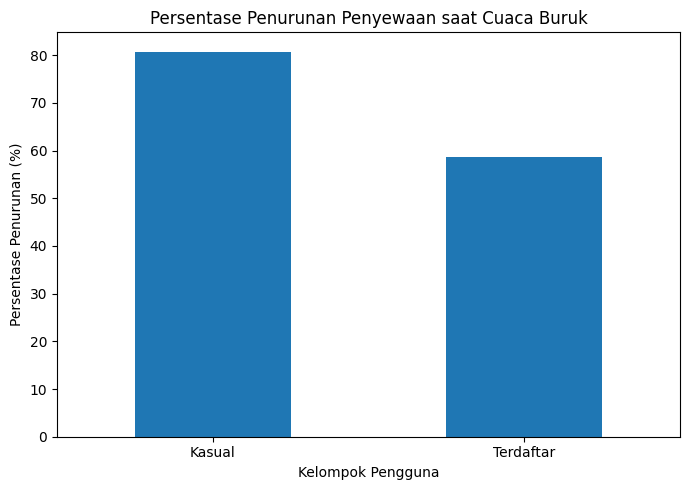

In [111]:
# Menyiapkan data persentase penurunan
decrease_data = pd.Series({
    "Kasual": penurunan["casual"],
    "Terdaftar": penurunan["registered"]
})

# Membuat grafik persentase penurunan
decrease_data.plot(kind="bar", figsize=(7, 5))

plt.title("Persentase Penurunan Penyewaan saat Cuaca Buruk")
plt.xlabel("Kelompok Pengguna")
plt.ylabel("Persentase Penurunan (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




```
# This is formatted as code
```

### Pertanyaan 3: Pada jam berapa rata-rata jumlah penyewaan sepeda paling tinggi dan paling rendah, serta pada jam berapa jumlah penyewaan mengalami perubahan paling besar selama periode 2011–2012?

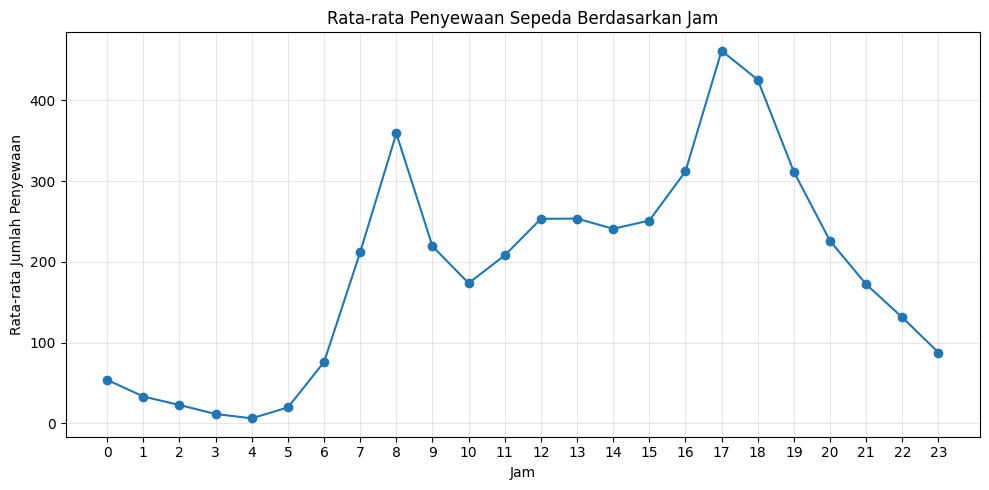

In [37]:

# Menghitung rata-rata penyewaan berdasarkan jam
hourly_plot = hour_df.groupby("hr")["cnt"].mean()

# Membuat grafik garis
plt.figure(figsize=(10, 5))
plt.plot(hourly_plot.index, hourly_plot.values, marker="o")

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Conclusion pertanyaan 1: Rata-rata penyewaan sepeda paling tinggi terjadi pada musim Fall, sekitar 5.644 penyewaan per hari. Sementara itu, musim Spring memiliki rata-rata penyewaan paling rendah, sekitar 2.604 penyewaan per hari.

- **Conclusion pertanyaan 2:** Penyewaan sepeda menurun saat cuaca buruk, baik pada pengguna kasual maupun pengguna terdaftar. Pengguna kasual mengalami penurunan lebih besar, yaitu 80,76%, dibandingkan pengguna terdaftar sebesar 58,65%.

- **Conclusion pertanyaan 3:** Penyewaan sepeda paling tinggi terjadi pada pukul 17.00, dengan rata-rata 461,45 penyewaan, sedangkan yang paling rendah terjadi pada pukul 04.00, dengan rata-rata 6,35 penyewaan. Kenaikan terbesar terjadi dari pukul 16.00 ke 17.00.

**Rekomendasi Action Item:**
- Menambah kesiapan dan ketersediaan sepeda menjelang sore, terutama sekitar pukul 16.00–17.00, untuk memenuhi tingginya permintaan.

- Menyesuaikan ketersediaan sepeda dengan pola permintaan setiap musim, terutama pada musim Fall yang memiliki rata-rata penyewaan tertinggi.

- Membuat promosi atau penawaran khusus bagi pengguna kasual saat cuaca kurang mendukung untuk mendorong penyewaan.